# 05 · Credit scoring function: score scale, risk bands, policy
**African Credit Scoring Challenge**

The challenge's second deliverable is to turn the production model's probability of default (PD) into something a lender
uses every day: a **points score** and a small set of **risk bands**, each with a decision policy. This notebook:

1. Defines the score scale (points to double the odds) and checks it.
2. Measures ranking power in the language credit teams use (Gini, KS).
3. Sets five bands, A (safest) to E, and tests that default rates rise steadily from band to band.
4. Stress-tests the bands: within products, across vintages, and forward in time (with recalibration).
5. Shows the business view: approval rate vs defaults avoided, exposure and expected loss per band.
6. Applies the scorecard to the test set, including Ghana, and writes the outputs the API deploys.

Inputs are the notebook 04 outputs only (`scores_p1_oof.csv`, `scores_p1_test.csv`, `model_settings.json`); the forward
check refits P1 on pre-2023 loans. Code lives in `credit_scoring/scorecard.py` (re-exported as `src/scorecard.py`), which the API uses unchanged.
Full run: about 2-3 minutes.

In [1]:
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, 'src')
from features import build_features
from modeling import lgbm_factory, platt_recalibrator
from scorecard import (ScoreScale, DEFAULT_BANDS, OVERLAYS, pd_to_score, score_to_pd, assign_band, band_bounds,
                       band_table, is_monotonic, adjacent_overlaps, cumulative_approval, gini_ks, psi, save_config)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
DATA, OUT = Path('.'), Path('outputs')
train = pd.read_csv(DATA / 'Train.csv', parse_dates=['disbursement_date', 'due_date'])
test  = pd.read_csv(DATA / 'Test.csv',  parse_dates=['disbursement_date', 'due_date'])
oof   = pd.read_csv(OUT / 'scores_p1_oof.csv')
tst   = pd.read_csv(OUT / 'scores_p1_test.csv')
SETTINGS = json.loads((OUT / 'model_settings.json').read_text())
assert (oof['ID'] == train['ID']).all() and (tst['ID'] == test['ID']).all(), 'score files out of row order'

y, p = oof['target'].to_numpy(), oof['pd_p1'].to_numpy()
core = (train['loan_type'].eq('Type_1') & train['duration'].eq(7)).to_numpy()     # the 2022 7-day Type_1 product
past = (train['disbursement_date'] < '2023-01-01').to_numpy()
print(f"{len(oof):,} training loans with out-of-fold PD (mean {p.mean():.2%} vs {y.mean():.2%} actual); "
      f"{len(tst):,} test loans.")

68,654 training loans with out-of-fold PD (mean 1.82% vs 1.83% actual); 18,594 test loans.


## 1. The score scale
Industry convention: **score = offset + factor × ln(good:bad odds)**, where every *PDO* points doubles the odds.
We use 600 points at 50:1 odds (PD ≈ 1.96%) and PDO = 20, clipped to 300-850. Higher score = safer. The scale is a
presentation choice: any increasing transform of PD ranks borrowers identically, so it changes no model result.

In [2]:
scale = ScoreScale()
anchor = pd.DataFrame({'pd': [0.001, 0.005, 0.01, 1 / 51, 0.05, 0.10, 0.20, 0.50]})
anchor['good_bad_odds'] = (1 - anchor['pd']) / anchor['pd']
anchor['score'] = pd_to_score(anchor['pd'], scale)
display(anchor.round(3))

p_check = np.linspace(0.0005, 0.9, 500)
assert np.allclose(score_to_pd(pd_to_score(p_check, scale), scale), p_check), 'score <-> PD must be invertible'
assert np.all(np.diff(pd_to_score(p_check, scale)) < 0), 'higher PD must always mean a lower score'
oof['score'] = pd_to_score(p, scale)
tst['score'] = pd_to_score(tst['pd_p1'], scale)
print(f"factor {scale.factor:.2f} points per unit of log-odds, offset {scale.offset:.1f}; "
      f"+{scale.pdo:.0f} points doubles the odds, e.g. PD {score_to_pd(600):.2%} at 600 vs {score_to_pd(620):.2%} at 620. "
      f"Training scores run {oof.score.min():.0f}-{oof.score.max():.0f} (median {oof.score.median():.0f}).")

,pd,good_bad_odds,score
0,0.001,999.0,686.410
1,0.005,199.0,639.855
2,0.010,99.0,619.710
3,0.020,50.0,600.000
4,0.050,19.0,572.081
5,0.100,9.0,550.521
6,0.200,4.0,527.123
7,0.500,1.0,487.123


factor 28.85 points per unit of log-odds, offset 487.1; +20 points doubles the odds, e.g. PD 1.96% at 600 vs 0.99% at 620. Training scores run 436-799 (median 639).


## 2. Ranking power in credit language
Gini (= 2 × AUC − 1) and KS (the largest gap between the cumulative score distributions of defaulters and
non-defaulters) are what a credit committee expects to see. Retail scorecards commonly report Gini of roughly
0.4-0.7 on application data.

In [3]:
power = pd.DataFrame({
    'all loans': gini_ks(y, oof.score),
    'Type_1 7-day': gini_ks(y[core], oof.score[core]),
    'other products': gini_ks(y[~core], oof.score[~core]),
}).T
display(power.round(3))
print(f"Overall Gini {power.loc['all loans', 'gini']:.3f} and KS {power.loc['all loans', 'ks']:.3f}, but within products "
      f"Gini is {power.loc['Type_1 7-day', 'gini']:.3f} (Type_1 7-day) and {power.loc['other products', 'gini']:.3f} "
      f"(other products): part of the headline comes from telling the products apart.")

,auc,gini,ks
all loans,0.872,0.743,0.575
Type_1 7-day,0.799,0.597,0.454
other products,0.728,0.457,0.340


Overall Gini 0.743 and KS 0.575, but within products Gini is 0.597 (Type_1 7-day) and 0.457 (other products): part of the headline comes from telling the products apart.


## 3. Risk bands
Five bands on **round score cut-offs**: A ≥ 640, B 620-639, C 590-619, D 550-589, E < 550 (PD roughly < 0.5%,
0.5-1%, 1-2.6%, 2.6-10%, ≥ 10%). The cut-offs are a policy choice fixed before looking at band outcomes, not
optimised on the data, so testing them on the same out-of-fold predictions does not grade our own exam.
A good set of bands has (a) default rates rising steadily from A to E, (b) 95% intervals of neighbouring bands that do
not overlap, (c) predicted PD close to the actual rate in every band, and (d) no band too small to estimate.

,label,score_from,score_to,pd_from,pd_to,policy
band,,,,,,
A,Very low risk,640.0,850.0,0.0000,0.0050,Approve
B,Low risk,620.0,640.0,0.0050,0.0099,Approve
C,Moderate risk,590.0,620.0,0.0099,0.0275,Approve with standard limits
D,High risk,550.0,590.0,0.0275,0.1016,"Refer: manual review, smaller amount or risk-b..."
E,Very high risk,300.0,550.0,0.1016,0.9985,Decline


,loans,share_of_loans,defaults,share_of_defaults,predicted_pd,default_rate,ci_low,ci_high
band,,,,,,,,
A,33673,0.4905,62.0,0.0493,0.0017,0.0018,0.0014,0.0024
B,10413,0.1517,88.0,0.0700,0.0072,0.0085,0.0069,0.0104
C,14977,0.2182,251.0,0.1995,0.0164,0.0168,0.0148,0.0189
D,7058,0.1028,377.0,0.2997,0.0522,0.0534,0.0484,0.0589
E,2533,0.0369,480.0,0.3816,0.2001,0.1895,0.1747,0.2052


Default rate rises from 0.18% (A) to 18.95% (E), 103x; monotonic: True; overlapping neighbours: none; smallest band E with 2,533 loans and 480 defaults; largest predicted-vs-actual gap in band E (20.01% vs 18.95%).


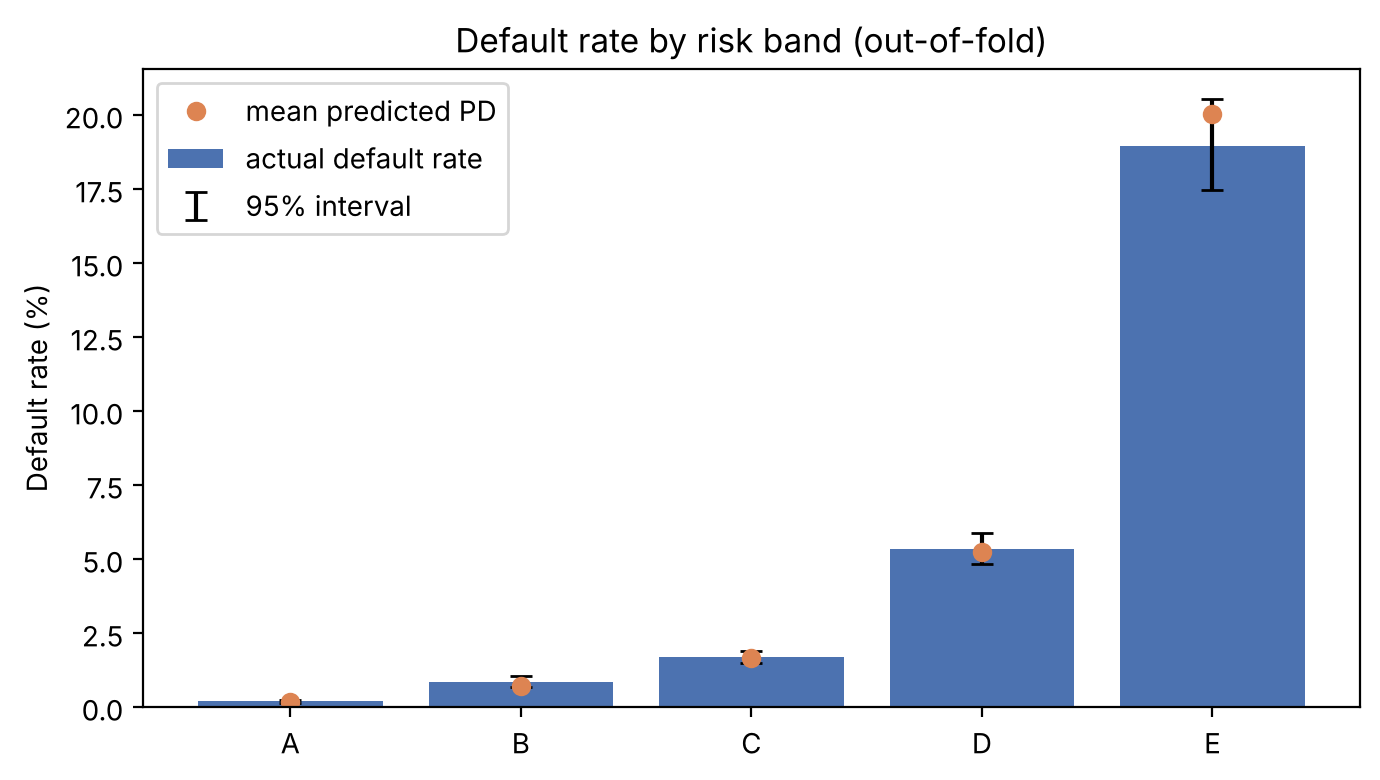

In [4]:
bounds = band_bounds(DEFAULT_BANDS, scale)
display(bounds.round(4))
oof['band'] = assign_band(oof.score)
exposure = train['Amount_Funded_By_Lender'].to_numpy()       # this lender's money at risk (KES)
bt = band_table(y, p, oof.band, exposure=exposure)
display(bt[['loans', 'share_of_loans', 'defaults', 'share_of_defaults', 'predicted_pd', 'default_rate',
            'ci_low', 'ci_high']].round(4))
mono, overlaps = is_monotonic(bt), adjacent_overlaps(bt)
worst_gap = (bt.predicted_pd - bt.default_rate).abs().idxmax()
print(f"Default rate rises from {bt.default_rate.iloc[0]:.2%} (A) to {bt.default_rate.iloc[-1]:.2%} (E), "
      f"{bt.default_rate.iloc[-1] / bt.default_rate.iloc[0]:.0f}x; monotonic: {mono}; overlapping neighbours: "
      f"{overlaps or 'none'}; smallest band {bt.loans.idxmin()} with {bt.loans.min():,} loans and "
      f"{bt.defaults[bt.loans.idxmin()]:.0f} defaults; largest predicted-vs-actual gap in band {worst_gap} "
      f"({bt.predicted_pd[worst_gap]:.2%} vs {bt.default_rate[worst_gap]:.2%}).")
assert mono and not overlaps, 'bands fail the basic test; revisit the cut-offs before going further'

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(bt))
ax.bar(x, bt.default_rate * 100, color='#4C72B0', label='actual default rate')
ax.errorbar(x, bt.default_rate * 100, yerr=[(bt.default_rate - bt.ci_low) * 100, (bt.ci_high - bt.default_rate) * 100],
            fmt='none', ecolor='black', capsize=4, label='95% interval')
ax.plot(x, bt.predicted_pd * 100, 'o', color='#DD8452', label='mean predicted PD')
ax.set(xticks=x, xticklabels=bt.index, ylabel='Default rate (%)', title='Default rate by risk band (out-of-fold)')
ax.legend(); plt.tight_layout(); plt.show()

## 4. Do the bands hold up?
Notebook 04 found that P1 ranks the riskier products much less well than it separates products, and that the
7-day Type_1 product disappeared after 2022. So the bands must be checked **within products**, **across vintages**,
and **forward in time**, not only on the pooled book.

### 4a. Within products

In [5]:
seg_tables = {name: band_table(y[m], p[m], oof.band[m]) for name, m in
              [('Type_1 7-day', core), ('other products', ~core)]}
for name, t in seg_tables.items():
    print(f"{name}:"); display(t[['loans', 'defaults', 'predicted_pd', 'default_rate', 'ci_low', 'ci_high']].round(4))
for name, t in seg_tables.items():
    usable = t[t.loans >= 100]
    print(f"{name}: monotonic across bands with at least 100 loans: {is_monotonic(usable)}; "
          f"bands under 100 loans: {t.index[t.loans < 100].tolist() or 'none'}; largest under-prediction "
          f"{(usable.default_rate - usable.predicted_pd).max():+.2%} in band {(usable.default_rate - usable.predicted_pd).idxmax()}.")

Type_1 7-day:


,loans,defaults,predicted_pd,default_rate,ci_low,ci_high
band,,,,,,
A,33626,62.0,0.0017,0.0018,0.0014,0.0024
B,10382,87.0,0.0072,0.0084,0.0068,0.0103
C,14360,225.0,0.0162,0.0157,0.0138,0.0178
D,3289,144.0,0.0434,0.0438,0.0373,0.0513
E,66,2.0,0.1188,0.0303,0.0083,0.1039


other products:


,loans,defaults,predicted_pd,default_rate,ci_low,ci_high
band,,,,,,
A,47,0.0,0.0024,0.0000,0.0000,0.0756
B,31,1.0,0.0077,0.0323,0.0057,0.1619
C,617,26.0,0.0200,0.0421,0.0289,0.0610
D,3769,233.0,0.0600,0.0618,0.0546,0.0700
E,2467,478.0,0.2023,0.1938,0.1786,0.2098


Type_1 7-day: monotonic across bands with at least 100 loans: True; bands under 100 loans: ['E']; largest under-prediction +0.12% in band B.
other products: monotonic across bands with at least 100 loans: True; bands under 100 loans: ['A', 'B']; largest under-prediction +2.21% in band C.


### 4b. Across vintages (half-years, out-of-fold)

In [6]:
half = train['disbursement_date'].dt.year.astype(str) + 'H' + np.where(train['disbursement_date'].dt.month <= 6, '1', '2')
vint = (oof.assign(half=half.values).groupby(['half', 'band']).agg(loans=('target', 'size'), default_rate=('target', 'mean'))
          .unstack('band'))
display(vint['loans'].fillna(0).astype(int))
display((vint['default_rate'] * 100).round(2))
usable = vint['loans'].fillna(0) >= 100
evaluable = [h for h in vint.index if usable.loc[h].sum() >= 2]
ok = [h for h in evaluable if is_monotonic(pd.DataFrame({'default_rate': vint.loc[h, 'default_rate'][usable.loc[h]]}))]
print(f"Half-years with at least two bands of 100+ loans: {len(evaluable)} of {len(vint)}; default rates rise A->E in "
      f"{len(ok)} of those {len(evaluable)} ({', '.join(ok)}). Outside 2022H2 almost no loans reach bands A-B.")

band,A,B,C,D,E
half,,,,,
2021H2,0,1,2,5,31
2022H1,0,5,66,543,450
2022H2,33667,10391,14511,4197,575
2023H1,2,3,80,280,164
2023H2,1,5,107,268,330
2024H1,3,4,24,158,109
2024H2,0,4,187,1607,874


band,A,B,C,D,E
half,,,,,
2021H2,NaN,0.00,50.00,0.00,64.52
2022H1,NaN,20.00,4.55,8.66,27.33
2022H2,0.18,0.84,1.59,4.53,16.17
2023H1,0.00,0.00,7.50,7.14,24.39
2023H2,0.00,0.00,3.74,4.85,18.18
2024H1,0.00,0.00,0.00,6.33,12.84
2024H2,NaN,0.00,3.74,6.04,14.87


Half-years with at least two bands of 100+ loans: 6 of 7; default rates rise A->E in 6 of those 6 (2022H1, 2022H2, 2023H1, 2023H2, 2024H1, 2024H2). Outside 2022H2 almost no loans reach bands A-B.


### 4c. Forward in time
P1 (production settings) is refitted on pre-2023 loans only, then scores 2023-24 loans. We band the raw scores, and
the scores after Platt recalibration fitted on 2023 outcomes and applied to 2024 (the routine recommended in notebook 04).

In [7]:
feats = build_features(train, test, pd.read_csv(DATA / 'economic_indicators.csv'))
P1, P1_PARAMS = SETTINGS['production']['features'], SETTINGS['production']['params']
X = feats.iloc[:len(train)][P1].reset_index(drop=True)
fwd_model = lgbm_factory(**P1_PARAMS)().fit(X[past], y[past])
p_fwd = np.full(len(y), np.nan)
p_fwd[~past] = fwd_model.predict_proba(X[~past])[:, 1]
y23 = (~past & (train['disbursement_date'] < '2024-01-01')).to_numpy()
y24 = (~past & (train['disbursement_date'] >= '2024-01-01')).to_numpy()
recal = platt_recalibrator(p_fwd[y23], y[y23])
p24_recal = recal(p_fwd[y24])

fwd_tables = {
    '2023-24, raw': band_table(y[~past], p_fwd[~past], assign_band(pd_to_score(p_fwd[~past]))),
    '2024, raw': band_table(y[y24], p_fwd[y24], assign_band(pd_to_score(p_fwd[y24]))),
    '2024, recalibrated on 2023': band_table(y[y24], p24_recal, assign_band(pd_to_score(p24_recal))),
}
for name, t in fwd_tables.items():
    print(f"{name}:"); display(t[['loans', 'defaults', 'predicted_pd', 'default_rate', 'ci_low', 'ci_high']].round(4))
for name, t in fwd_tables.items():
    usable = t[t.loans >= 100]
    print(f"{name}: {int((t.loans > 0).sum())} of {len(t)} bands populated ({', '.join(usable.index)} with 100+ loans); "
          f"rising across those: {is_monotonic(usable)}; overlapping neighbours: {adjacent_overlaps(usable) or 'none'}; "
          f"mean PD {np.average(t.predicted_pd.fillna(0), weights=t.loans):.1%} vs actual {t.defaults.sum() / t.loans.sum():.1%}.")

2023-24, raw:


,loans,defaults,predicted_pd,default_rate,ci_low,ci_high
band,,,,,,
A,31,2.0,0.0038,0.0645,0.0179,0.2072
B,150,11.0,0.0076,0.0733,0.0414,0.1265
C,1254,79.0,0.0207,0.0630,0.0508,0.0778
D,2116,222.0,0.0451,0.1049,0.0926,0.1187
E,659,87.0,0.2669,0.1320,0.1083,0.1600


2024, raw:


,loans,defaults,predicted_pd,default_rate,ci_low,ci_high
band,,,,,,
A,21,0.0,0.0039,0.0000,0.0000,0.1546
B,138,11.0,0.0076,0.0797,0.0451,0.1371
C,1119,69.0,0.0209,0.0617,0.0490,0.0773
D,1593,163.0,0.0397,0.1023,0.0884,0.1182
E,99,15.0,0.2448,0.1515,0.0940,0.2350


2024, recalibrated on 2023:


,loans,defaults,predicted_pd,default_rate,ci_low,ci_high
band,,,,,,
A,0,0.0,NaN,NaN,NaN,NaN
B,0,0.0,NaN,NaN,NaN,NaN
C,0,0.0,NaN,NaN,NaN,NaN
D,2790,234.0,0.0819,0.0839,0.0741,0.0947
E,180,24.0,0.1244,0.1333,0.0913,0.1907


2023-24, raw: 5 of 5 bands populated (B, C, D, E with 100+ loans); rising across those: False; overlapping neighbours: [('B', 'C'), ('D', 'E')]; mean PD 7.1% vs actual 9.5%.
2024, raw: 5 of 5 bands populated (B, C, D with 100+ loans); rising across those: False; overlapping neighbours: [('B', 'C')]; mean PD 3.8% vs actual 8.7%.
2024, recalibrated on 2023: 2 of 5 bands populated (D, E with 100+ loans); rising across those: True; overlapping neighbours: [('D', 'E')]; mean PD 8.4% vs actual 8.7%.


## 5. The business view
**Approval trade-off:** approving bands from A downwards, what share of loans is approved, what default rate does the
approved book carry, and what share of all defaults is declined? **Losses:** exposure is the lender's funded amount
(`Amount_Funded_By_Lender`, KES); expected loss = PD × exposure with **loss given default assumed 100%**, because we
have no recovery data, so these are upper bounds.

In [8]:
ca = cumulative_approval(bt)
display(ca.round(4))
money = bt[['exposure', 'expected_loss', 'realised_loss']].copy()
money['expected_loss_rate'] = money.expected_loss / money.exposure
money['realised_loss_rate'] = money.realised_loss / money.exposure
display(money.round(4))
c = ca.loc['C']
print(f"Approving A-C (declining D and E) approves {c.approval_rate:.1%} of loans at a {c.approved_default_rate:.2%} default rate "
      f"and declines {c.defaults_declined:.1%} of all defaulters; bands D and E hold "
      f"{money.loc[['D', 'E'], 'realised_loss'].sum() / money.realised_loss.sum():.0%} of realised losses on "
      f"{money.loc[['D', 'E'], 'exposure'].sum() / money.exposure.sum():.0%} of exposure. Expected loss "
      f"{money.expected_loss.sum():,.0f} vs realised {money.realised_loss.sum():,.0f} KES in total.")

,approval_rate,approved_default_rate,defaults_declined
approve_down_to,,,
A,0.4905,0.0018,0.9507
B,0.6421,0.0034,0.8808
C,0.8603,0.0068,0.6812
D,0.9631,0.0118,0.3816
E,1.0000,0.0183,0.0000


,exposure,expected_loss,realised_loss,expected_loss_rate,realised_loss_rate
band,,,,,
A,48734589.01,1.170431e+05,129290.50,0.0024,0.0027
B,25138540.96,1.812738e+05,282307.19,0.0072,0.0112
C,47659737.88,7.969792e+05,1133283.87,0.0167,0.0238
D,20352234.63,1.115645e+06,1077137.44,0.0548,0.0529
E,32884859.12,1.054040e+07,11761094.73,0.3205,0.3576


Approving A-C (declining D and E) approves 86.0% of loans at a 0.68% default rate and declines 68.1% of all defaulters; bands D and E hold 89% of realised losses on 30% of exposure. Expected loss 12,751,345 vs realised 14,383,114 KES in total.


## 6. Applying the scorecard to the test set
Kenya test should look like training (population stability index, PSI, < 0.10). Ghana is the new market: we compare
its mean PD with the default rate estimated from the leaderboard probes (notebook 04) (a diagnostic, never used to fit
anything), and route every Ghana loan, and every loan with an unseen lender or product, to manual review via an overlay.

In [9]:
tst['band'] = assign_band(tst.score)
ke, gh = tst.country_id.eq('Kenya').to_numpy(), tst.country_id.eq('Ghana').to_numpy()
dist = pd.DataFrame({'train (out-of-fold)': oof.band.value_counts(normalize=True),
                     'Kenya test': tst.band[ke].value_counts(normalize=True),
                     'Ghana test': tst.band[gh].value_counts(normalize=True)}).reindex([b.name for b in DEFAULT_BANDS]).fillna(0)
display(dist.round(3))
psi_ke, psi_gh = psi(oof.band, tst.band[ke]), psi(oof.band, tst.band[gh])

# Ghana default rate implied by the three leaderboard scores (outputs/leaderboard_scores.csv): F1 = 2TP / (pred + actual)
lb = pd.read_csv(OUT / 'leaderboard_scores.csv').set_index('submission')
sub = pd.read_csv(OUT / 'sub_m4_r1.csv')
P_k = int(sub.target[ke].sum()); P_g = int(sub.target[gh].sum()); N_g = int(gh.sum())
A_k = y.mean() * ke.sum()                                         # Kenya test assumed to default at the training rate
est = {}
for split in ['public_f1', 'private_f1']:
    F0 = lb.loc['Probe: Ghana all 0', split]
    F1 = lb.loc['Probe: Ghana all 1', split]
    G = (F1 * (P_k + N_g + A_k) - F0 * (P_k + A_k)) / (2 + F0 - F1)
    est[split] = G / N_g
print(f"PSI vs training: Kenya test {psi_ke:.3f} ({'stable' if psi_ke < 0.10 else 'shifted'}), Ghana {psi_gh:.2f} "
      f"({'stable' if psi_gh < 0.10 else 'major shift'}). Ghana mean PD {tst.pd_p1[gh].mean():.1%} vs a default rate of "
      f"{est['public_f1']:.1%} (public) / {est['private_f1']:.1%} (private) implied by the leaderboard probes, and "
      f"{(tst.band[gh].isin(['D', 'E'])).mean():.0%} of Ghana loans fall in bands D-E vs {(tst.band[ke].isin(['D', 'E'])).mean():.0%} in Kenya.")

,train (out-of-fold),Kenya test,Ghana test
band,,,
A,0.490,0.486,0.003
B,0.152,0.159,0.015
C,0.218,0.220,0.252
D,0.103,0.103,0.531
E,0.037,0.033,0.199


PSI vs training: Kenya test 0.001 (stable), Ghana 3.72 (major shift). Ghana mean PD 12.4% vs a default rate of 13.1% (public) / 12.6% (private) implied by the leaderboard probes, and 73% of Ghana loans fall in bands D-E vs 14% in Kenya.


In [10]:
seen_lender, seen_type = set(train.lender_id.astype(str)), set(train.loan_type)
unknown = ~test.lender_id.astype(str).isin(seen_lender) | ~test.loan_type.isin(seen_type)
overlay = np.where(gh, 'new_market', np.where(unknown, 'unknown_code', ''))
band_policy = {b.name: b.policy for b in DEFAULT_BANDS}
tst['overlay'] = overlay
tst['decision'] = [OVERLAYS[o] if o else band_policy[b] for o, b in zip(overlay, tst.band)]
tst['decision_short'] = tst.decision.str.split(':').str[0]
display(pd.crosstab(tst.decision_short, tst.country_id, margins=True))
print(f"Kenya test: {(tst.decision_short[ke] == 'Approve').mean():.1%} approved outright, "
      f"{tst.decision_short[ke].str.startswith('Approve').mean():.1%} approved in total, "
      f"{(tst.decision_short[ke] == 'Refer').mean():.1%} referred, {(tst.decision_short[ke] == 'Decline').mean():.1%} declined; "
      f"unseen codes in Kenya: {int(unknown[ke].sum())}. All {int(gh.sum()):,} Ghana loans are referred by the new-market overlay.")

country_id,Ghana,Kenya,All
decision_short,,,
Approve,0,9722,9722
Approve with standard limits,0,3308,3308
Decline,0,493,493
Refer,3525,1546,5071
All,3525,15069,18594


Kenya test: 64.5% approved outright, 86.5% approved in total, 10.3% referred, 3.3% declined; unseen codes in Kenya: 0. All 3,525 Ghana loans are referred by the new-market overlay.


## 7. Save the scorecard for the API

In [11]:
save_config(OUT / 'scorecard.json', scale, DEFAULT_BANDS)
bt.join(bounds[['label', 'score_from', 'score_to', 'pd_from', 'pd_to', 'policy']]).to_csv(OUT / 'scorecard_table.csv')
tst[['ID', 'country_id', 'pd_p1', 'score', 'band', 'overlay', 'decision']].assign(score=lambda d: np.floor(d.score)) \
   .to_csv(OUT / 'scores_test_banded.csv', index=False)
print('Saved outputs/scorecard.json, outputs/scorecard_table.csv, outputs/scores_test_banded.csv')

Saved outputs/scorecard.json, outputs/scorecard_table.csv, outputs/scores_test_banded.csv


## 8. Assumptions log (scorecard)
Statuses reflect the outputs above.

| # | Assumption | Evidence | Status |
| --- | --- | --- | --- |
| 17 | 600 points at 50:1 odds, PDO 20, is a suitable scale | Presentation convention; any increasing transform ranks identically | Adopted |
| 18 | Band cut-offs are fixed round scores, not fitted | Section 3; no optimisation on outcomes | Adopted |
| 19 | Default rates rise steadily A→E | Section 3: 0.18% → 18.95% (103x), no overlapping 95% intervals, predicted within 1.1 points of actual in every band | Holds |
| 20 | Bands hold within products | Section 4a: rising in both product groups, but for other products band C predicts 2.0% and defaults at 4.2%; other products barely reach A-B, Type_1 7-day barely reaches E | **Partly**: add a product-group adjustment or monitor band C for non-Type_1 loans |
| 21 | Bands hold across vintages (in time) | Section 4b: rising in every half-year with two or more bands of 100+ loans | Holds in time |
| 22 | Bands hold forward in time | Section 4c: raw forward scores put A-C at about 6-7% default (indistinguishable) and only D-E separate; recalibrating on 2023 fixes the level (8.4% vs 8.7%) by moving every 2024 loan into D-E | **Fails as relative ranking; works as an absolute scale**: the 2023+ book really is a D-level book. Recalibrate monthly and re-validate bands on matured vintages |
| 23 | Exposure = `Amount_Funded_By_Lender`; loss given default 100% | No recovery data | Assumed: expected losses are upper bounds |
| 24 | Ghana level matches P1's mean PD | Section 6: mean PD 12.4% vs 12.6-13.1% implied by the leaderboard probes (diagnostic only); Ghana PSI 3.7 | Level plausible; ranking unverified, so Ghana stays on the referral overlay |